#### Imports

In [80]:
import os
#os.chdir(os.path.dirname(__file__))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import welch
from pathlib import Path

offset = 2.5
gain = 0.4
PGAgain = [1, 1, 1, 1, 1, 1, 1]
RFs=[50e3, 1e6, 5e6, 100e6, 10e6, 1000e6, 100e6]
# RFs= RFs[::-1]
data_path = r"I:\test light"

detector = 6


#### Helper Functions

In [50]:
def grab_path(path):
    """Get the path to the output folder (3rd item in directory listing)"""
    items = os.listdir(path)
    items.sort()  # Sort to ensure consistent ordering
    name = items[0]  # Get the first subfolder (equivalent to listing(3) in MATLAB)
    return os.path.join(path, name, f"output {name}")

def get_name(path):
    """Get the name of the first subfolder"""
    items = os.listdir(path)
    items.sort()
    return items[0]

def get_time_domain(path, channels):
    """Load ADC data from CSV file"""
    patient1 = grab_path(path)
    raw_adc = f"{patient1}(parsedADC).csv"
    
    table_adc = pd.read_csv(raw_adc)

    
    # Extract channels and apply gain
    ch_raw = []
    channel_names = ['ch1Volts', 'ch2Volts', 'ch3Volts', 'ch4Volts', 'ch5Volts', 'ch6Volts', 'ch7Volts']
    selected_channel_names = [channel_names[i] for i in channels]
    
    for i, ch_name in enumerate(selected_channel_names):
        if ch_name in table_adc.columns:
            ch_data = (((table_adc[ch_name].values * 4.096) / (2**23)) / gain) / PGAgain[i] + offset
            ch_raw.append(ch_data)
    
    return ch_raw

def parse_settings_file(txt_path):
    """Parse the settings text file to extract lock-in frequencies and sampling frequency"""
    with open(txt_path, 'r') as f:
        lines = f.readlines()
    
    # Find Lock-in Frequencies
    lockin_freqs = None
    for i, line in enumerate(lines):
        if "Lock-in Freq" in line:
            # Skip header and LED1/LED2 row
            if i + 2 < len(lines):
                freq_line = lines[i + 2].strip().split()
                lockin_freqs = np.array([float(f) for f in freq_line if f])
            break
    
    # Find Sampling Frequency
    fs = None
    for i, line in enumerate(lines):
        if "Sampling Frequency" in line:
            if i + 1 < len(lines):
                sfreq_str = lines[i + 1].strip().replace("kHz", "").strip()
                fs = float(sfreq_str) * 1000  # Convert kHz to Hz
            break
    
    return lockin_freqs, fs
    """Compute segment-length thresholds (in seconds) at requested percentiles.

    For each percentile (e.g., 95), returns the segment length such that that
    percentage of segments is at or below this value.
    """
    segment_lengths = np.asarray(segment_lengths)
    segment_lengths = np.sort(segment_lengths)[::-1]
    cumsum_lengths = np.cumsum(segment_lengths)
    total_length = cumsum_lengths[-1]
    cumulative_percentages = (cumsum_lengths / total_length) * 100
    thresholds = []
    for p in percentiles:
        idx = np.searchsorted(cumulative_percentages, p)
        threshold_samples = segment_lengths[idx] if idx < len(segment_lengths) else segment_lengths[-1]
        threshold_seconds = threshold_samples / Fs
        thresholds.append(threshold_seconds)
    thresholds = np.array(thresholds)
    return thresholds

In [51]:
print(os.getcwd())
file_path = os.path.join( "noise_vs_amp_Raw.csv")
# read in the csv data
noise_df = pd.read_csv(file_path)
print(noise_df.head())

# Normalize column names from the CSV to the expected names
noise_df = noise_df.rename(columns={
    'voltages': 'Voltage (V)',
    'pks_avg': 'Peak-to-Peak Noise (V)'
})

voltages = noise_df['Voltage (V)'].values
pks_avg = noise_df['Peak-to-Peak Noise (V)'].values

c:\Users\Kourosh Vali\OneDrive - University of California, Davis\Documents\GitHub\Wavelet-EKG\Wavelet-EKG
      pks_avg  voltages
0 -124.975038      3.20
1 -126.869175      2.38
2 -128.725077      1.77
3 -130.881273      1.31
4 -133.456161      0.72


### MAIN SCRIPT
#### Data loading and preprocessing


In [81]:
saving = False

path = Path(data_path)
sub_folder_name1 = Path(data_path).name

# Load data

path_weird_name = grab_path(path)
txt_path = path_weird_name + "(settings).txt"
raw_time_domain_data = get_time_domain(path, channels=[detector - 1])  # Load only channel 1 for now; adjust index for 0-based Python indexing

lockin_freqs, Fs = parse_settings_file(txt_path)

#### Plot time domain

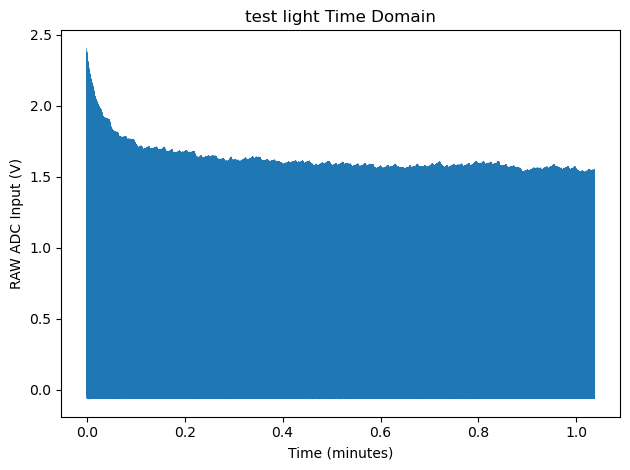

In [82]:
#detector_data = raw_time_domain_data[detector]
detector_data = raw_time_domain_data[0]
time = np.arange(len(detector_data)) / Fs / 60  # Convert to minutes

plt.figure()
plt.plot(time, detector_data, linewidth=0.2)
plt.xlabel('Time (minutes)')
plt.ylabel('RAW ADC Input (V)')
plt.title(f"{sub_folder_name1} Time Domain")
plt.tight_layout()
plt.show()

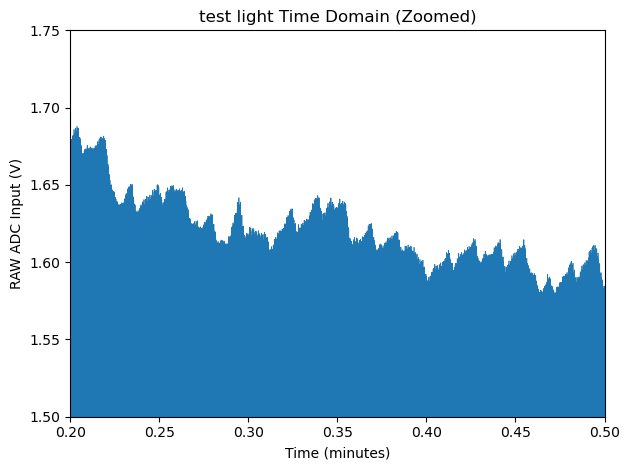

In [91]:
beginTime = 0.2
endTime = 0.5
# mask data from {beginTime} to {endTime} minutes
mask = (time >= beginTime) & (time <= endTime)
mask_data = detector_data[mask]
mask_time = time[mask]

plt.figure()
plt.plot(mask_time, mask_data, linewidth=0.5)
plt.xlabel('Time (minutes)')
plt.ylabel('RAW ADC Input (V)')
plt.title(f"{sub_folder_name1} Time Domain (Zoomed)")
plt.xlim(beginTime, endTime)  # Set x-axis limits to the range of the data
plt.tight_layout()
#plt.xlim(beginTime, beginTime + 0.002)
plt.ylim(1.5, 1.75)
# plt.xlim(0.492,0.494)
plt.show()

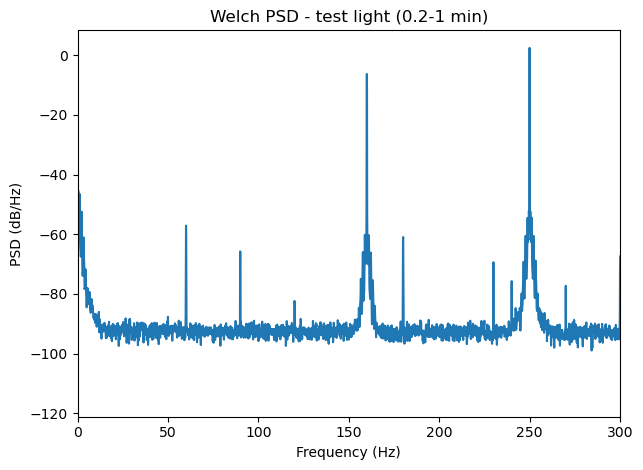

In [84]:
# 60 s Hann window with 90% overlap
nperseg = int(10 * Fs)
noverlap = int(0.9 * nperseg)
window = np.hanning(nperseg)

f, Pxx = welch(
    mask_data,
    fs=Fs,
    window=window,
    nperseg=nperseg,
    noverlap=noverlap,
    detrend='constant',
    scaling= 'density',       #    'density',      'spectrum',
    return_onesided=True
)

# Convert PSD to dB/Hz (avoid log of zero)
Pxx = 10 * np.log10(np.maximum(Pxx, np.finfo(float).tiny))

plt.figure()
plt.plot(f, Pxx)
plt.xlabel('Frequency (Hz)')
plt.ylabel('PSD (dB/Hz)')
plt.title(f'Welch PSD - {sub_folder_name1} ({beginTime}-{endTime} min)')
plt.tight_layout()
plt.xlim(0, 300)
plt.show()

In [85]:
# Thermal noise floor calculation
R = RFs[detector-1]
k = 1.380649e-23
T = 300
thermal_noise_psd = 10 * np.log10(4 * k * T * R)  # in dB/Hz
print(f"Thermal Noise PSD: {thermal_noise_psd:.2f} dB/Hz")

Thermal Noise PSD: -107.81 dB/Hz


In [86]:
# Shot noise floor calculation
q = 1.602176634e-19  # Elementary charge in Coulombs

mean_TIA_output = abs(np.mean(mask_data)) 
photocurrent = mean_TIA_output / R
shot_noise_psd = (2 * q * photocurrent) ** 0.5  # in A/Hz^0.5
# convert to V/Hz^0.5 using TIA gain (R)
shot_noise_psd_volts = shot_noise_psd * R
shot_noise_psd_db = 20 * np.log10(shot_noise_psd_volts)  # Convert to dB/Hz^0.5
print(f"Shot Noise PSD: {shot_noise_psd_db:.2f} dBV/Hz^0.5")

Shot Noise PSD: -96.11 dBV/Hz^0.5


In [87]:
from scipy.interpolate import interp1d

# compute mean-subtracted RMS and convert to peak-to-peak amplitude

rms_val = np.sqrt(np.mean(((mask_data*gain*PGAgain[detector-1]) - np.mean(mask_data*gain*PGAgain[detector-1]))**2))
mean_amplitude = rms_val * np.sqrt(2) * 2

idx = np.argsort(voltages)
expected_adc_noise = interp1d(
    voltages[idx],
    pks_avg[idx],
    kind='linear',
    fill_value='extrapolate'
)(mean_amplitude)

print(f"Expected ADC Noise (Peak-to-Peak): {expected_adc_noise:.4f} V")


Expected ADC Noise (Peak-to-Peak): -133.7647 V


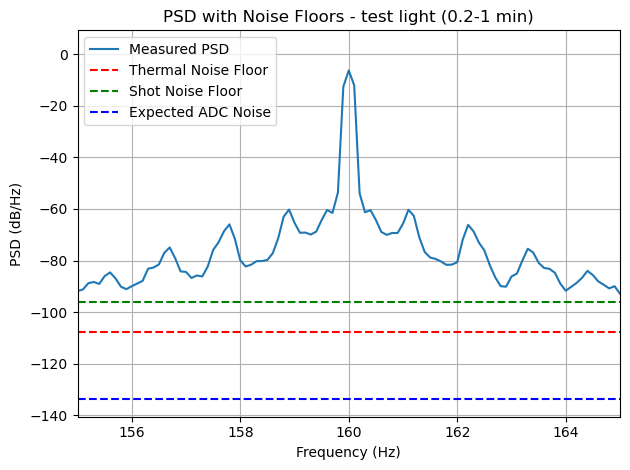

In [88]:
# Plot thermal noise floor and shot noise floor and expected ADC noise on the PSD plot
plt.figure()
plt.plot(f, Pxx, label='Measured PSD')
plt.axhline(thermal_noise_psd, color='r', linestyle='--', label='Thermal Noise Floor')
plt.axhline(shot_noise_psd_db, color='g', linestyle='--', label='Shot Noise Floor')
plt.axhline(expected_adc_noise, color='b', linestyle='--', label='Expected ADC Noise')
plt.xlabel('Frequency (Hz)')
plt.ylabel('PSD (dB/Hz)')
plt.title(f'PSD with Noise Floors - {sub_folder_name1} ({beginTime}-{endTime} min)')
plt.legend(loc='upper left')
plt.tight_layout()
plt.xlim(155, 165)
plt.grid()
plt.show()